# Elbow/UCL latent signals and advance warning

**Question:** Do the existing supervised directions show persistent case/control differences, a change approaching injury, or heterogeneous individual paths? Can PLS preserve validation ranking with fewer dimensions than PCA?

This notebook adds four focused visuals to the frozen supervised-reduction study. It does **not** fit new models, replace prior results, or equate latent separation with a deployable warning system. The established **Elbow / UCL** target is broader than confirmed UCL injury; explicitly documented UCL support is audited below.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/ucl_latent_visuals.yaml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.ucl_latent_visuals import run,read_table,OUT
from src.injury_analysis.ucl_latent_report import write_summary
from src.injury_analysis import ucl_latent_plots as plots
summary=run()
write_summary()
display(read_table('cohort_support'))
display(read_table('endpoint_definition_audit'))
def finding(number):
    r=read_table('figure_summary').iloc[number-1]
    display(Markdown('**Computed result.** '+r.main_result+'\n\n**Interpretation.** '+r.profile_or_imminence))

Elbow/UCL: 92 matched pairs; 62 balanced five-outing pairs. No model refitting.


,cohort,events,pitchers,initial_explicit_ucl_events,later_supplemental_ucl_confirmation
0,All eligible proxy events,650,501,58,147
1,Out-of-training matched pairs,92,88,5,24
2,Balanced five outings,62,60,4,15
3,Balanced calendar bins,32,32,3,8


,season,elbow_ucl_proxy_events,initial_explicit_ucl_events,later_supplemental_ucl_confirmation
0,2015,35,2,13
1,2016,46,2,12
2,2017,45,4,8
3,2018,54,10,16
4,2019,61,8,11
5,2020,41,8,10
6,2021,27,1,1
7,2022,53,3,11
8,2023,67,4,15
9,2024,73,8,16


## Frozen design and component selection

Transforms, imputation/scaling, and classifiers were fit through 2021. Component counts were selected on 2022–2023 validation AP in the prior stage. No component is chosen from the appearance of its held-out trajectory. We retain all two departure and five combined axes in the heatmap, emphasize the two largest training standardized logit weights per block, and use the largest-weight departure axis for individual events.

Scores are oriented using the frozen logistic coefficient and divided by their **training score SD**. Positive means a larger conditional logit contribution, not a calibrated probability. The bases are the actual orthonormalized nested PLS coordinates used by the existing classifier.

The matched analysis reuses original pair identities and outing keys, requires both windows/anchors in the already examined 2022–2025 period, and requires complete P+D fields. No imputed measurement creates a plotted biological trajectory. Every time point within an alignment uses the same event pairs. Calendar and outing panels have different balanced cohorts.

The 300 bootstrap draws keep connected pairs sharing **either case or control pitchers** together, including pitchers switching roles. Joint bands cover all retained components × positions within an alignment and group. Shape-contrast intervals are descriptive, without a joint correction across contrasts. Models, matching, and dimension selection remain fixed.

In [2]:
display(read_table('component_selection')[['component','block','retained_axes','design_columns',
 'training_absolute_standardized_logit_weight','primary_trajectory','individual_heatmap']])
display(read_table('component_interpretation'))

,component,block,retained_axes,design_columns,training_absolute_standardized_logit_weight,primary_trajectory,individual_heatmap
0,D1,Departure,2,10,0.264919,1,True
1,D2,Departure,2,10,0.050539,1,False
2,C1,Combined,5,23,0.429740,1,False
3,C2,Combined,5,23,0.148358,1,False
4,C3,Combined,5,23,0.064414,0,False
5,C4,Combined,5,23,0.050017,0,False
6,C5,Combined,5,23,0.000111,0,False


,component,profile_squared_weight,departure_squared_weight,top_features,training_absolute_standardized_logit_weight
0,D1,0.000000,1.000000,velo_z (-0.880; 77.4% squared weight); spin_z ...,0.264919
1,D2,0.000000,1.000000,spin_z (+0.773; 59.7% squared weight); extensi...,0.050539
2,C1,0.542157,0.457843,velo_z (-0.595; 35.4% squared weight); days_si...,0.429740
3,C2,0.767408,0.232592,velo_z (-0.420; 17.6% squared weight); age_at_...,0.148358
4,C3,0.645879,0.354121,spin_z (+0.517; 26.7% squared weight); observe...,0.064414
5,C4,0.921399,0.078601,prior_reported_il_count (+0.695; 48.3% squared...,0.050017
6,C5,0.594172,0.405828,days_since_mlb_debut (+0.569; 32.4% squared we...,0.000111


## 1. Component trajectories: offset versus approach-to-event change

The case/control curves use five unsmoothed observed outings. The annotated contrast is `(case − control at −1) − (case − control at −5)`. Use paired contrasts, rather than whether separate case/control bands overlap, to assess divergence. A constant offset would concern profile/relative-level differences, not injury imminence. A null interval does not prove no effect.

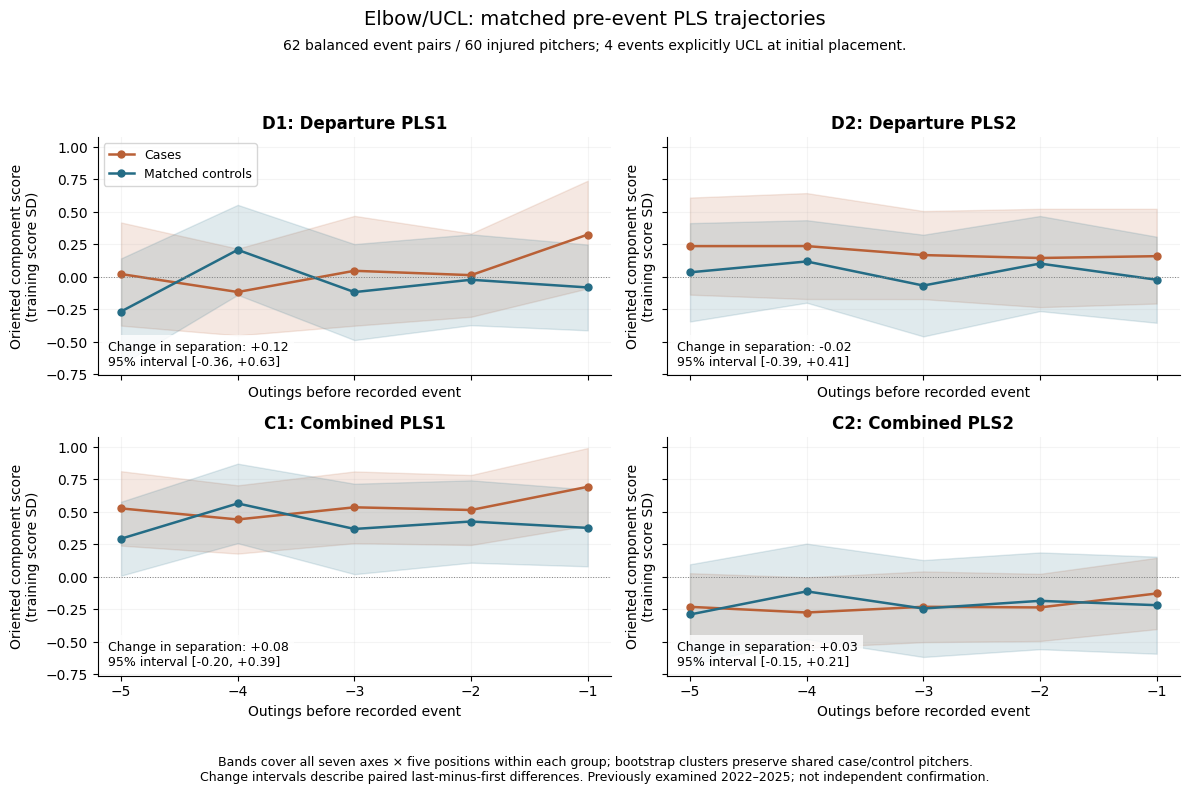

**Computed result.** 62 balanced pairs. D1 paired last-minus-first change +0.12 [-0.36, +0.63] SD; C1 +0.08 [-0.20, +0.39] SD.

**Interpretation.** Neither a stable susceptibility offset nor a shared imminent-warning rise is clearly established in these matched means.

,component,mode,metric,mean,low,high,events,pitchers,bootstrap_clusters
0,C1,appearance,average_separation,0.136234,-0.051107,0.326522,62,60,54
3,C1,appearance,last_minus_first_separation,0.083028,-0.196287,0.389748,62,60,54
8,C2,appearance,average_separation,-0.010217,-0.232983,0.184515,62,60,54
11,C2,appearance,last_minus_first_separation,0.031248,-0.151839,0.213030,62,60,54
40,D1,appearance,average_separation,0.113969,-0.116793,0.323918,62,60,54
43,D1,appearance,last_minus_first_separation,0.118742,-0.364153,0.633020,62,60,54
48,D2,appearance,average_separation,0.155750,-0.045429,0.355580,62,60,54
51,D2,appearance,last_minus_first_separation,-0.020273,-0.389925,0.414932,62,60,54


,appearance_before,n,median,q25,q75,minimum,maximum
0,1,62,1.0,1.00,1.0,1,8
1,2,62,5.5,4.00,7.0,2,14
2,3,62,9.0,7.00,13.0,4,38
3,4,62,12.5,10.00,19.0,7,43
4,5,62,16.5,12.25,25.0,9,48


In [3]:
plots.trajectory_figure();plt.show()
finding(1)
display(read_table('trajectory_shape_summary').query("mode=='appearance' and component in ['D1','D2','C1','C2'] and metric in ['average_separation','last_minus_first_separation']"))
display(read_table('outing_calendar_support'))

## 2. Component × lead-time separation

Each cell is the equal-event-weighted matched difference in training component SD units. The zero-centered scale is shared across panels. A dot would indicate that the joint interval excludes zero. A colored cell without support is not an estimated onset of warning.

Calendar bins average available measurements separately within each event/group/bin before pairing; events do not gain more weight by making more appearances. No smoothing, interpolation, or per-event normalization is used. Later retained axes may have negligible classifier weight, so geometric separation and predictive contribution are distinct.

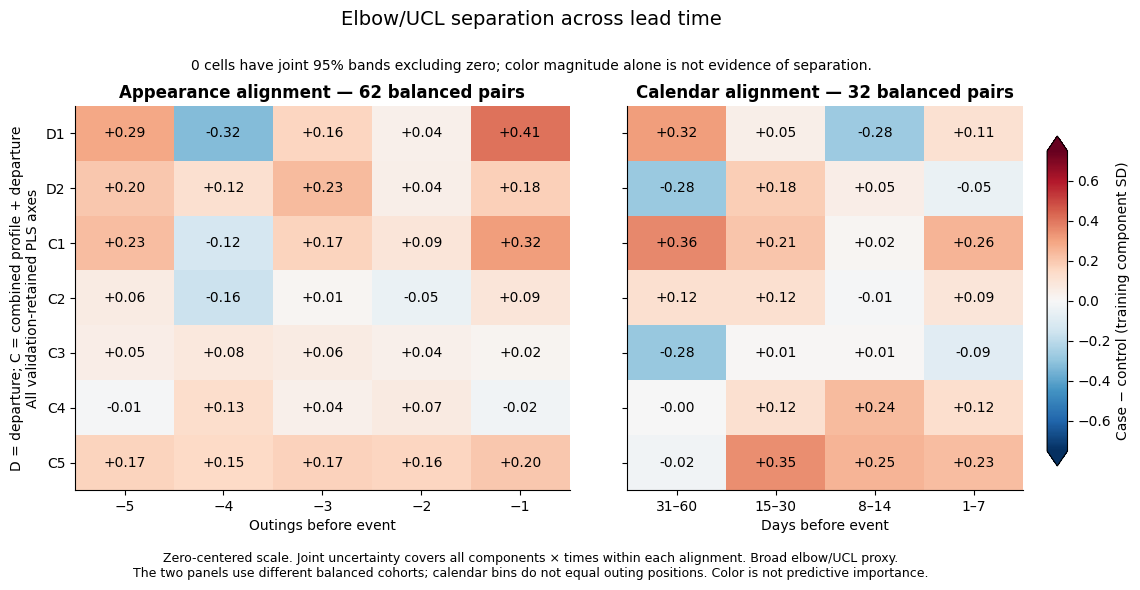

**Computed result.** 0/63 cells have joint 95% bands excluding zero; 62 outing pairs and 32 calendar pairs.

**Interpretation.** Inspect persistent versus late patterns, but no supported onset of divergence can be assigned from color alone.

,events,pitchers,bootstrap_clusters
mode,,,
appearance,62,60,54
calendar,32,32,29


In [4]:
plots.lead_time_heatmap();plt.show()
finding(2)
display(read_table('balanced_trajectories').groupby('mode')[['events','pitchers','bootstrap_clusters']].first())

## 3. Validation compression performance

Reuse the actual original validation AP curves: same labels, rows, candidate counts, L2 logistic classifier, and training-only preprocessing within each representation. Squares mark the **existing** validation-selected count. Each reference line uses unreduced inputs from that panel, not an unrelated feature set.

Binary context and missingness indicators bypass projection; component count is not total model dimension. These are selection-period curves, so apparent peaks are optimistic. The finite grid does not establish an exact optimum or a confidence-based plateau. Practical event warnings remain the relevant downstream comparison.

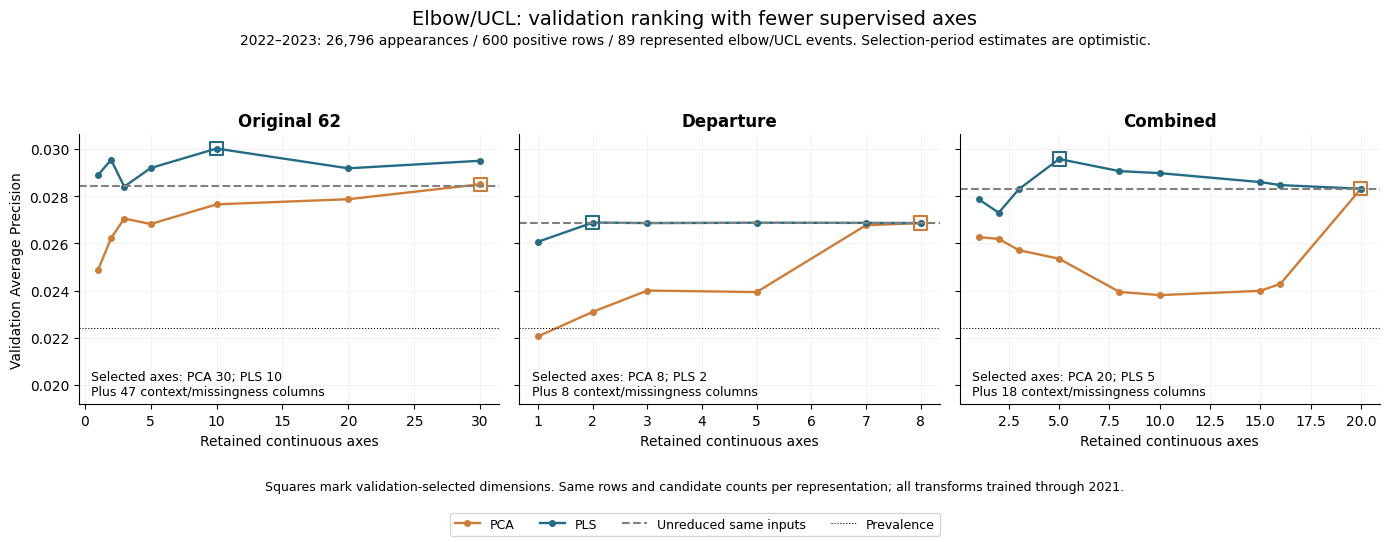

**Computed result.** Original inputs: PLS 10 versus PCA 30 selected axes; validation AP 0.0300 versus 0.0285, unreduced 0.0284.

**Interpretation.** Supervision can compress ranking information; the curve does not distinguish susceptibility from imminence.

,block,method,selected_components,continuous_features,passthrough_columns,design_columns,validation_ap,training_variance_retained,plateau_components
0,Original 62,PCA,30,60,47,77,0.028498,0.900213,30.0
1,Original 62,PLS,10,60,47,57,0.030012,0.417808,10.0
4,Departure,PCA,8,8,8,16,0.026857,1.000000,7.0
5,Departure,PLS,2,8,8,10,0.026877,0.247988,2.0
6,Combined,PCA,20,20,18,38,0.028309,1.000000,20.0
7,Combined,PLS,5,20,18,23,0.029569,0.315257,5.0


,partition,ap_difference,ap_low,ap_high,event_mean,event_low,event_high
0,validation,0.001596,-0.001605,0.004212,0.058333,0.023701,0.103758
3,test,0.003945,-0.000128,0.010098,0.006897,-0.040268,0.052517


,partition,variant,qualifying_events,observable_events,alerted_events,injury_event_recall,median_warning_lead_days
2,validation,Unreduced,120,80,12,0.100000,16.0
14,validation,PLS selected,120,80,19,0.158333,15.0
18,test,Unreduced,145,104,26,0.179310,17.5
30,test,PLS selected,145,104,27,0.186207,16.0


In [5]:
plots.compression_figure();plt.show()
finding(3)
display(read_table('compression_summary').query("block in ['Original 62','Departure','Combined']"))
display(read_table('ucl_selected_differences').query("block=='Original 62' and variant=='PLS selected' and reference=='Unreduced'")[
 ['partition','ap_difference','ap_low','ap_high','event_mean','event_low','event_high']])
display(read_table('ucl_alert_budgets').query("block=='Original 62' and alert_rate==0.05 and variant in ['Unreduced','PLS selected']")[[
 'partition','variant','qualifying_events','observable_events','alerted_events','injury_event_recall','median_warning_lead_days']])

## 4. Individual-event heterogeneity

Each row is one original matched event pair. All three panels share row order, chosen descriptively by case score at the final outing minus the first two outings' average. This sorting necessarily creates an ordered gradient; it is **not** clustering or evidence for injury phenotypes.

Scores keep a fixed training-derived origin and scale. Case-minus-control values provide the comparison that is missing from an unpaired event-only heatmap. Colors clip at ±3 SD; the CSV cells are not clipped. IDs, names, dates and initially explicit UCL flags are in the row-lookup table. Increasing D1 or crossing zero is not a prespecified clinical alert rule.

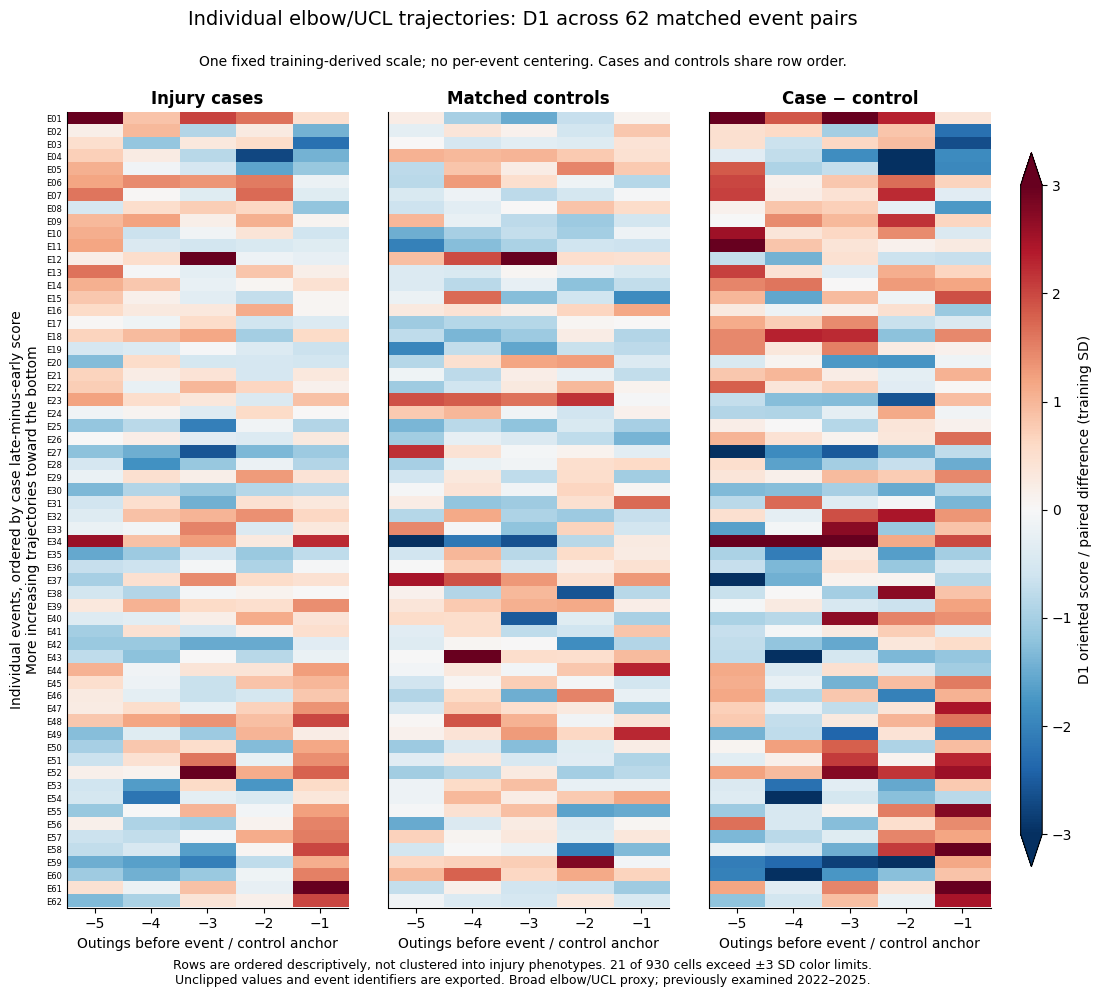

**Computed result.** D1 final-minus-early score rises in 40/62 cases and 26/62 matched controls; case IQR [-0.38, +0.92] SD.

**Interpretation.** Persistent, rising, falling and irregular paths coexist; ordering exposes variation without identifying phenotypes.

,kind,events,increasing_events,decreasing_events,unchanged_events,mean,median,q25,q75,minimum,maximum,contrast
0,Injury,62,40,22,0,0.372842,0.360222,-0.383201,0.918610,-2.057848,3.150651,Final outing minus mean of first two outings
1,Control,62,26,36,0,-0.052172,-0.162522,-0.781335,0.742560,-2.641179,4.004392,Final outing minus mean of first two outings
2,difference,62,39,23,0,0.425015,0.514976,-0.935424,1.601018,-3.499354,3.676281,Final outing minus mean of first two outings


,injury_event_id,player_id,player_name,anchor_date,initial_explicit_ucl,row_number,event_label,case_late_minus_early,case_mean_score,case_final_score
0,dafa10ed89d3cf696b69a68ac6adc2d2,663978,Chris Paddack,2022-05-09,False,1,E01,-2.057848,1.844100,0.485413
1,35c60394c60b37b21166db644c288d26,680694,Kyle Bradish,2024-06-15,True,2,E02,-1.994234,-0.179516,-1.423326
2,6a0505e212c3e69b7881b72dbe2c13ed,640462,A.J. Puk,2025-04-18,False,3,E03,-1.910109,-0.410858,-2.244322
3,0cb9a4054a059bd70cffce4d8b58d3cf,664849,Danny Young,2025-04-27,False,4,E04,-1.896203,-0.808551,-1.421194
4,fe0b62e00b79f9129228ca8c0aea16d7,700363,AJ Smith-Shawver,2025-05-29,False,5,E05,-1.629177,-0.452621,-1.145720
5,53ab6305d06f6f50cebe223b2a88e170,676534,Calvin Faucher,2023-06-06,False,6,E06,-1.481034,1.059908,-0.180741
6,c4b8b0cebc1352240df5a25495c97433,673380,Dedniel Núñez,2025-07-03,False,7,E07,-1.189677,0.528158,-0.362247
7,6be70a52da2760d947125c49a25fdaa5,640451,Hunter Harvey,2023-07-16,False,8,E08,-1.186295,0.040342,-1.174321
8,e27e13fce8d41eb795ba9670d008fb45,679885,Justin Martinez,2025-06-10,True,9,E09,-1.009949,0.699571,0.076582
9,caf358fef13bf926ca99257a0773d565,657585,Reed Garrett,2024-07-10,False,10,E10,-0.812208,0.026627,-0.591940


In [6]:
plots.individual_heatmap();plt.show()
finding(4)
display(read_table('individual_shape_distribution'))
display(read_table('individual_event_order').head(10))

## What these visuals support

Read the computed per-figure table below together with its uncertainty. Compression, group separation, and advance warning answer different questions. Components are weighted combinations of measured pitching variables, not physiological mechanisms. Recorded IL/injury timing is not biological onset, surgery timing, or return timing. Current-outing predictors are only available after an outing is completed.

Before a UCL-specific warning study, adjudicate the intended endpoint and freeze the horizon, feature/trajectory definitions, and validation-selected threshold. The last observed outing is often much less than seven days before the recorded event. Test a predeclared useful lead window and controlled alert budget in an untouched future chronological cohort.

Four figures are sufficient here. Family interpretation is tabulated; existing refit stability is not UCL-specific, and calendar mean contrasts cannot substitute for separately evaluated horizon-specific predictive relevance.

In [7]:
display(read_table('figure_summary'))
print('Summary, captions and tables:',OUT/'SUMMARY.md')
print('Publication exports:',OUT/'figures')

,figure,question,main_result,profile_or_imminence,development_use
0,01_ucl_pls_matched_trajectories,Persistent offset or increasing case–control d...,62 balanced pairs. D1 paired last-minus-first ...,Neither a stable susceptibility offset nor a s...,D1 prioritizes lower velocity relative to pers...
1,02_ucl_component_lead_time_heatmap,When does matched separation emerge across ret...,0/63 cells have joint 95% bands excluding zero...,"Inspect persistent versus late patterns, but n...",Prevents selecting a lead-time window from the...
2,03_ucl_pca_pls_compression,How compact is predictive information compared...,Original inputs: PLS 10 versus PCA 30 selected...,Supervision can compress ranking information; ...,A smaller candidate representation is feasible...
3,04_individual_ucl_latent_trajectories,Does the average hide heterogeneous individual...,D1 final-minus-early score rises in 40/62 case...,"Persistent, rising, falling and irregular path...",Requires prospective event-level warning evalu...


Summary, captions and tables: /Users/garrettgall/Desktop/MLB pitch stats/mlb_ucl_project/reports/injury_supervised_reduction/ucl_focus/SUMMARY.md
Publication exports: /Users/garrettgall/Desktop/MLB pitch stats/mlb_ucl_project/reports/injury_supervised_reduction/ucl_focus/figures
